# ColorMNIST Simulation Results

DR-CPME + IMQ MMD flow. Two sweeps: sample size $n_{\mathrm{obs}}$ (at $w = 10$)
and confounding strength $w$ (at $n_{\mathrm{obs}} = 20000$, the Figure-3
experiment of Dance et al., 2026). 10 and 3 DGP seeds respectively, 3 repeats,
both arms.

The headline metric is the DecFM paper's: **SW2 in flat pixel space between the
decoded flow output and held-out counterfactual samples** (1000 projections),
arms averaged within each run, repeats within each seed, mean $\pm$ sd across
seeds. "No flow" scores the observed arm the same way; "floor" is
counterfactual-vs-counterfactual.

In [1]:
import glob

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 140)


def load_results(pattern):
    "Concatenate every parsable task CSV (skips files a running task has not filled)."
    frames = []
    for f in sorted(glob.glob(pattern)):
        try:
            frames.append(pd.read_csv(f))
        except Exception:
            pass
    frame = pd.concat(frames, ignore_index=True)
    print(f"{len(frames)} files -> {len(frame)} rows")
    return frame


def headline(frame, value, by):
    '''Mean +/- sd of `value` vs the swept parameter(s) `by`.

    Aggregation order (the DecFM paper convention): arms averaged within each
    run first, then repeats within each data seed, then mean +/- sd across seeds.
    '''
    per_run = frame.groupby([*by, "data_seed", "repeat"])[value].mean()
    per_seed = per_run.groupby([*by, "data_seed"]).mean()
    return per_seed.groupby(list(by)).agg(["mean", "std"])


def sweep_table(frame, columns, by):
    "One table: each (column -> label) as `mean +- sd` against the swept parameter."
    out = {}
    for column, label in columns.items():
        stats = headline(frame, column, by)
        out[label] = (stats["mean"].map("{:.4f}".format) + " ± "
                      + stats["std"].map("{:.4f}".format))
    return pd.DataFrame(out)


def sweep_plot(ax, frame, columns, by, xlabel, logx=True):
    "Flow curve with a seed band; baselines as plain lines."
    styles = {"flow": ("tab:blue", "-"), "no flow": ("tab:red", ":"),
              "floor": ("tab:green", "--")}
    for column, label in columns.items():
        key = ("flow" if "flow" in label and "no" not in label
               else "no flow" if "no" in label else "floor")
        color, ls = styles[key]
        stats = headline(frame, column, by)
        ax.plot(stats.index, stats["mean"], marker="o", ms=4, color=color,
                linestyle=ls, label=label)
        if key == "flow":
            ax.fill_between(stats.index, stats["mean"] - stats["std"],
                            stats["mean"] + stats["std"], color=color, alpha=0.15)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("pixel SW2 to counterfactual samples")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)

results_n = load_results("../ColorMNIST/dr_mmd_flow/results/colormnist_refparams_*.csv")
results_w = load_results("../ColorMNIST/dr_mmd_flow/results/colormnist_wsweep_*.csv")
COLUMNS = {"sw2_flow": "SW2 flow", "sw2_initial": "SW2 no flow",
           "sw2_floor": "SW2 floor"}

50 files -> 300 rows
30 files -> 180 rows


## SW2 vs sample size

In [2]:
sweep_table(results_n, COLUMNS, ["n_obs"])

,SW2 flow,SW2 no flow,SW2 floor
n_obs,,,
2000,0.0195 ± 0.0015,0.0440 ± 0.0009,0.0121 ± 0.0004
5000,0.0130 ± 0.0010,0.0425 ± 0.0009,0.0080 ± 0.0002
10000,0.0115 ± 0.0005,0.0426 ± 0.0007,0.0071 ± 0.0002
15000,0.0115 ± 0.0009,0.0426 ± 0.0006,0.0071 ± 0.0002
20000,0.0114 ± 0.0005,0.0427 ± 0.0005,0.0071 ± 0.0002


## SW2 vs confounding strength (Figure 3)

In [3]:
sweep_table(results_w, COLUMNS, ["w_conf"])

,SW2 flow,SW2 no flow,SW2 floor
w_conf,,,
1.0,0.0083 ± 0.0003,0.0113 ± 0.0008,0.0072 ± 0.0003
2.0,0.0088 ± 0.0007,0.0170 ± 0.0006,0.0072 ± 0.0003
3.0,0.0086 ± 0.0006,0.0222 ± 0.0005,0.0072 ± 0.0003
4.0,0.0091 ± 0.0007,0.0277 ± 0.0002,0.0072 ± 0.0003
5.0,0.0089 ± 0.0004,0.0317 ± 0.0002,0.0072 ± 0.0003
6.0,0.0094 ± 0.0003,0.0354 ± 0.0008,0.0072 ± 0.0003
7.0,0.0097 ± 0.0003,0.0387 ± 0.0003,0.0072 ± 0.0003
8.0,0.0101 ± 0.0006,0.0407 ± 0.0006,0.0072 ± 0.0003
9.0,0.0109 ± 0.0006,0.0420 ± 0.0001,0.0072 ± 0.0003


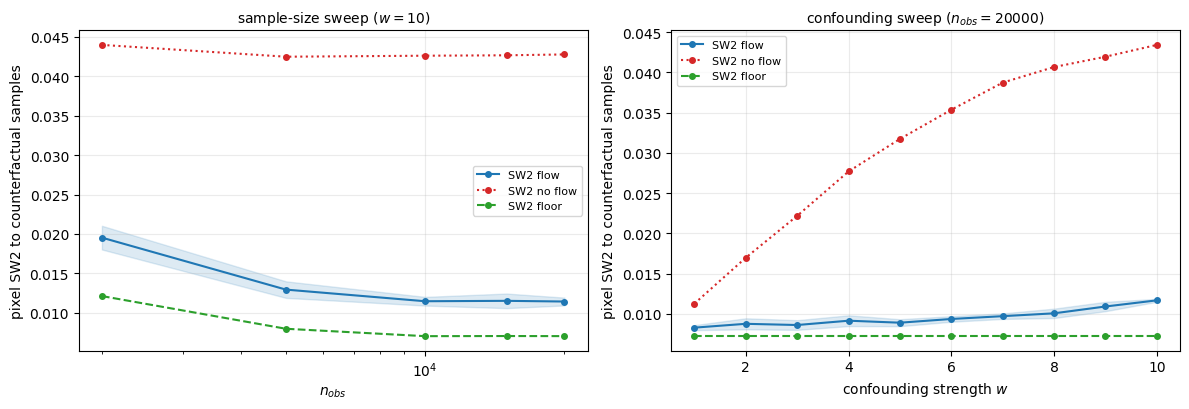

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sweep_plot(axes[0], results_n, COLUMNS, ["n_obs"], "$n_{obs}$")
axes[0].set_title("sample-size sweep ($w = 10$)", fontsize=10)
sweep_plot(axes[1], results_w, COLUMNS, ["w_conf"], "confounding strength $w$",
           logx=False)
axes[1].set_title("confounding sweep ($n_{obs} = 20000$)", fontsize=10)
fig.tight_layout()
plt.show()

## Initialisation ablation

Do the particles have to start from the observed arm? Two Gaussian inits are compared
against it at a fixed configuration: $N(0, I)$, and the empirical $N(\mu, \Sigma)$ of
the flow's target support (its first two moments, correlations included). Both are
drawn in the coordinates the flow operates in. The `observed` row is the matching
main-sweep run restricted to the ablation's seeds.

The `*_initial` columns are omitted here: under a Gaussian init they describe the
starting cloud rather than the observed arm, so they are not a common baseline.

In [5]:
ablation = load_results("../ColorMNIST/dr_mmd_flow/results/colormnist_initablation_*.csv")
baseline = load_results("../ColorMNIST/dr_mmd_flow/results/colormnist_refparams_nobs20000_*.csv")
baseline["init"] = "observed"
init_runs = pd.concat([ablation, baseline[baseline.data_seed.isin(ablation.data_seed.unique())]],
                      ignore_index=True)
INIT_COLUMNS = {"sw2_flow": "SW2 flow", "colour_mean_flow": "colour flow",
                "sw2_floor": "SW2 floor"}
print(f"oracle colour = {init_runs.colour_mean_oracle.mean():.3f}")
sweep_table(init_runs, INIT_COLUMNS, ["init"])

6 files -> 30 rows
10 files -> 60 rows
oracle colour = 0.505


,SW2 flow,colour flow,SW2 floor
init,,,
moment,0.0172 ± 0.0008,0.4916 ± 0.0073,0.0071 ± 0.0004
normal,0.0221 ± 0.0008,0.4941 ± 0.0069,0.0072 ± 0.0003
observed,0.0117 ± 0.0003,0.4946 ± 0.0060,0.0072 ± 0.0003


## Summary

- **Sample size**: SW2 falls $0.0195 \to 0.0114$ from $n = 2000$ to $20000$ and
  saturates at $n \ge 10000$ (the DR support is capped at 4000 rows).
- **Confounding (Figure 3)**: the uncorrected arm degrades $0.0113 \to 0.0434$
  across $w = 1..10$ while the DR flow moves only $0.0083 \to 0.0117$ against a
  flat floor of $0.0072$ — at $w = 10$ it still removes $\approx 89\%$ of the
  baseline's excess.
- **Initialisation**: the flow recovers the colour *statistic* from any start
  ($0.492$–$0.495$ against an oracle $0.505$), but the pixel *distribution*
  degrades with a worse start — SW2 $0.0117$ (observed) $\to 0.0172$
  ($N(\mu,\Sigma)$) $\to 0.0221$ ($N(0,I)$), floor $0.0072$. Second-moment
  knowledge recovers about half the gap.